# 8. Model Building

## 1. Introduction

The objective of this stage is to build and compare
different Machine Learning classification algorithms.

The following models will be investigated:

1. Logistic Regression
2. Random Forest
3. XGBoost

Each model will be trained using a complete Machine Learning
pipeline containing:

- Feature Engineering
- Preprocessing
- Optional Sampling
- Classification Algorithm

The validation set will be used for model comparison.

In [1]:
import pandas as pd
import numpy as np

from collections import Counter

from sklearn.model_selection import train_test_split

from src.config import (
    CLEANED_DATA_PATH,
    TARGET_COLUMN,
    RANDOM_STATE,
    TEST_SIZE,
)

df = pd.read_csv(CLEANED_DATA_PATH)

X = df.drop(columns=[TARGET_COLUMN])

y = df[TARGET_COLUMN]

X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    stratify=y_development,
    random_state=RANDOM_STATE
)

print("Training:", X_train.shape)
print("Validation:", X_validation.shape)

Training: (182276, 30)
Validation: (45569, 30)


## 2. Model Selection

### Logistic Regression

A linear classification algorithm that estimates the probability
of a transaction belonging to the fraud class.

### Random Forest

An ensemble learning algorithm that combines multiple decision
trees to improve predictive performance.

### XGBoost

A gradient boosting algorithm that builds decision trees
sequentially to minimize a specified loss function.

The algorithms will be evaluated using Average Precision,
Recall, Precision, F1-Score, and ROC-AUC.

In [2]:
from src.train import (
    train_model,
    get_model,
    build_pipeline,
)

from src.evaluate import (
    get_prediction_probabilities,
    calculate_metrics,
)

## 3. Baseline Models Without Sampling

The first experiment trains the models using the original
training class distribution.

This experiment establishes a baseline for comparison
against sampling-based strategies.

In [3]:
baseline_models = {}

baseline_model_names = [
    "logistic_regression",
    "random_forest",
    "xgboost",
]

for model_name in baseline_model_names:

    try:

        print(f"\nTraining {model_name}...")

        model = train_model(
            X_train,
            y_train,
            model_name=model_name,
            sampling_method="none"
        )

        baseline_models[model_name] = model

        print(f"{model_name} training completed.")

    except ImportError as error:

        print(error)


Training logistic_regression...
logistic_regression training completed.

Training random_forest...
random_forest training completed.

Training xgboost...
xgboost training completed.


In [4]:
baseline_results = []

for model_name, model in baseline_models.items():

    y_validation_prob = get_prediction_probabilities(
        model,
        X_validation
    )

    metrics = calculate_metrics(
        y_validation,
        y_validation_prob,
        threshold=0.50
    )

    metrics["model"] = model_name

    metrics["sampling"] = "none"

    baseline_results.append(metrics)

baseline_results_df = pd.DataFrame(
    baseline_results
)

display(
    baseline_results_df.sort_values(
        by="average_precision",
        ascending=False
    )
)

,threshold,accuracy,precision,recall,f1_score,roc_auc,average_precision,mcc,balanced_accuracy,model,sampling
2,0.5,0.999495,0.951613,0.746835,0.836879,0.974350,0.845590,0.842797,0.873385,xgboost,none
1,0.5,0.999473,0.936508,0.746835,0.830986,0.933641,0.818925,0.836066,0.873374,random_forest,none
0,0.5,0.998947,0.829787,0.493671,0.619048,0.964925,0.722183,0.639580,0.746748,logistic_regression,none


## 4. Models with SMOTE

SMOTE is now introduced as an alternative strategy.

The sampling operation is included inside the training pipeline.

During training, synthetic minority-class observations
are generated using training data only.

The validation set remains unchanged.

In [5]:
smote_models = {}

for model_name in baseline_model_names:

    try:

        print(f"\nTraining {model_name} with SMOTE...")

        model = train_model(
            X_train,
            y_train,
            model_name=model_name,
            sampling_method="smote"
        )

        smote_models[model_name] = model

        print(f"{model_name} with SMOTE completed.")

    except ImportError as error:

        print(error)


Training logistic_regression with SMOTE...
logistic_regression with SMOTE completed.

Training random_forest with SMOTE...
random_forest with SMOTE completed.

Training xgboost with SMOTE...
xgboost with SMOTE completed.


In [6]:
smote_results = []

for model_name, model in smote_models.items():

    y_validation_prob = get_prediction_probabilities(
        model,
        X_validation
    )

    metrics = calculate_metrics(
        y_validation,
        y_validation_prob,
        threshold=0.50
    )

    metrics["model"] = model_name

    metrics["sampling"] = "smote"

    smote_results.append(metrics)

smote_results_df = pd.DataFrame(
    smote_results
)

display(
    smote_results_df.sort_values(
        by="average_precision",
        ascending=False
    )
)

,threshold,accuracy,precision,recall,f1_score,roc_auc,average_precision,mcc,balanced_accuracy,model,sampling
1,0.5,0.999451,0.897059,0.772152,0.829932,0.971977,0.813880,0.831999,0.885999,random_forest,smote
2,0.5,0.997059,0.351351,0.822785,0.492424,0.969919,0.781098,0.536569,0.910073,xgboost,smote
0,0.5,0.973271,0.054033,0.873418,0.101770,0.969812,0.682102,0.213465,0.923431,logistic_regression,smote


## 5. Model Comparison

The baseline and SMOTE experiments are combined.

The main comparison metric is Average Precision.

Recall and Precision are also important because fraud detection
requires identifying fraudulent transactions while controlling
false alarms.

The final model will be selected using validation performance.

In [7]:
all_results = pd.concat(
    [
        baseline_results_df,
        smote_results_df
    ],
    ignore_index=True
)

all_results = all_results.sort_values(
    by="average_precision",
    ascending=False
)

display(all_results)

,threshold,accuracy,precision,recall,f1_score,roc_auc,average_precision,mcc,balanced_accuracy,model,sampling
2,0.5,0.999495,0.951613,0.746835,0.836879,0.974350,0.845590,0.842797,0.873385,xgboost,none
1,0.5,0.999473,0.936508,0.746835,0.830986,0.933641,0.818925,0.836066,0.873374,random_forest,none
4,0.5,0.999451,0.897059,0.772152,0.829932,0.971977,0.813880,0.831999,0.885999,random_forest,smote
5,0.5,0.997059,0.351351,0.822785,0.492424,0.969919,0.781098,0.536569,0.910073,xgboost,smote
0,0.5,0.998947,0.829787,0.493671,0.619048,0.964925,0.722183,0.639580,0.746748,logistic_regression,none
3,0.5,0.973271,0.054033,0.873418,0.101770,0.969812,0.682102,0.213465,0.923431,logistic_regression,smote


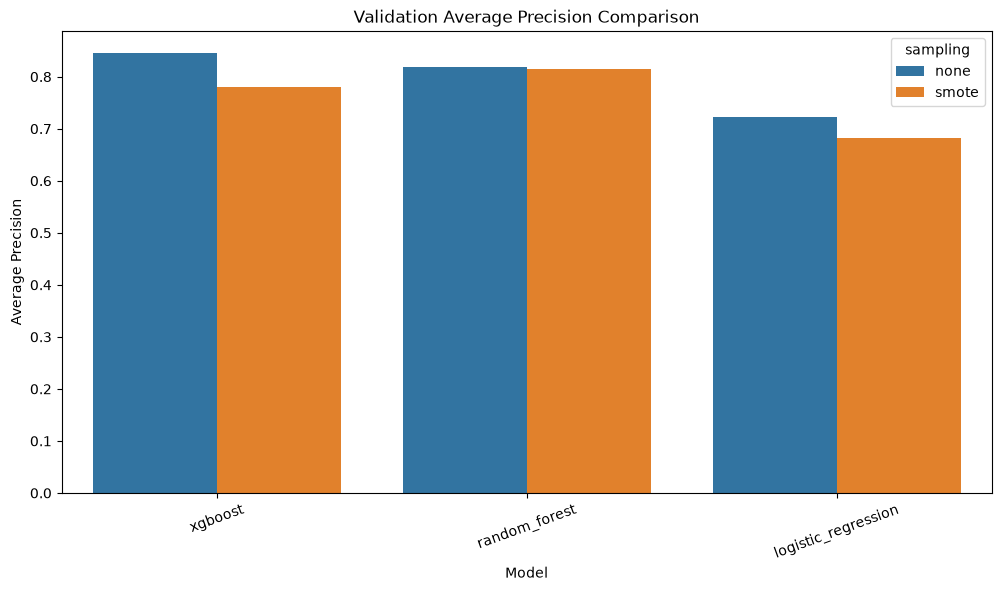

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results,
    x="model",
    y="average_precision",
    hue="sampling"
)

plt.title("Validation Average Precision Comparison")

plt.ylabel("Average Precision")

plt.xlabel("Model")

plt.xticks(rotation=20)

plt.show()

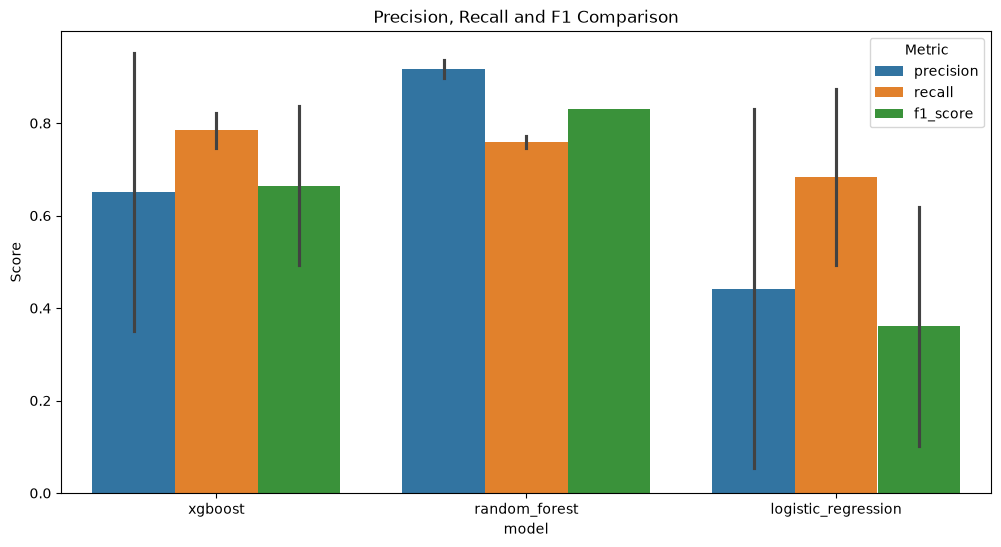

In [9]:
comparison_metrics = all_results.melt(
    id_vars=["model", "sampling"],
    value_vars=["precision", "recall", "f1_score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_metrics,
    x="model",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 Comparison")

plt.show()

## 6. Model Selection Decision

The model selection decision must be based on actual validation
results.

The following questions should be addressed:

1. Which model achieves the highest Average Precision?
2. Which model achieves the highest Recall?
3. What is the Precision associated with the Recall?
4. Does SMOTE improve validation performance?
5. Which model provides the most suitable balance?

The selected model will proceed to hyperparameter tuning.

The test dataset has not been used for this selection.

In [10]:
best_experiment = all_results.iloc[0]

best_model_name = best_experiment["model"]

best_sampling_method = best_experiment["sampling"]

print("Best Model:", best_model_name)

print("Sampling Method:", best_sampling_method)

print(
    "Validation Average Precision:",
    best_experiment["average_precision"]
)

Best Model: xgboost
Sampling Method: none
Validation Average Precision: 0.8455898166910489
